# IMPORT dan Load Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df =pd.read_csv('insurance.csv')

# Deskripsi dan Visualisasi Data


<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 94.5 KB



,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


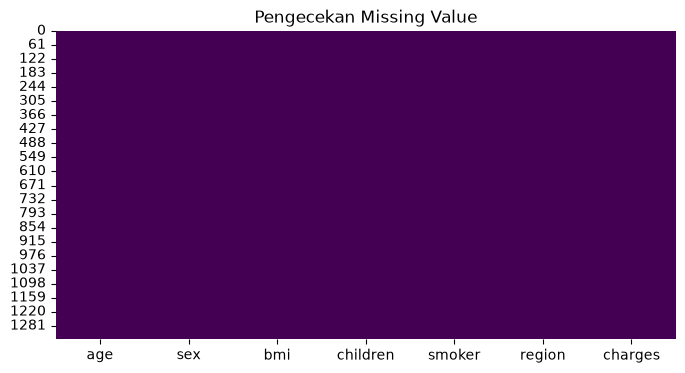

In [2]:
print()
df.info()

print()
display(df.describe())

plt.figure(figsize=(8, 4))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis')
plt.title('Pengecekan Missing Value')
plt.show()

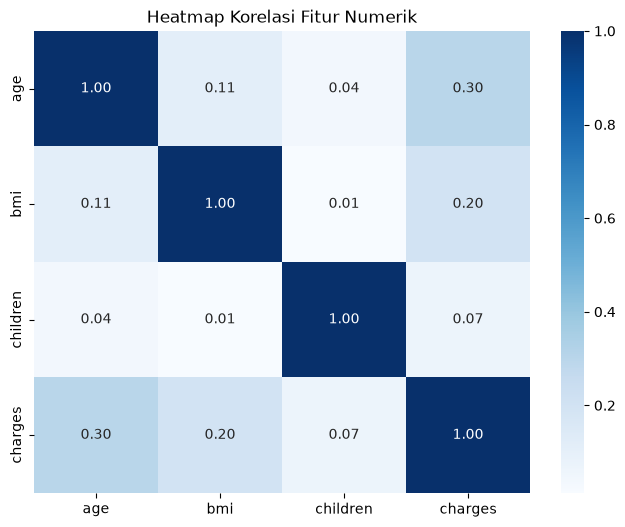

In [3]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='Blues', fmt='.2f')
plt.title('Heatmap Korelasi Fitur Numerik')
plt.show()

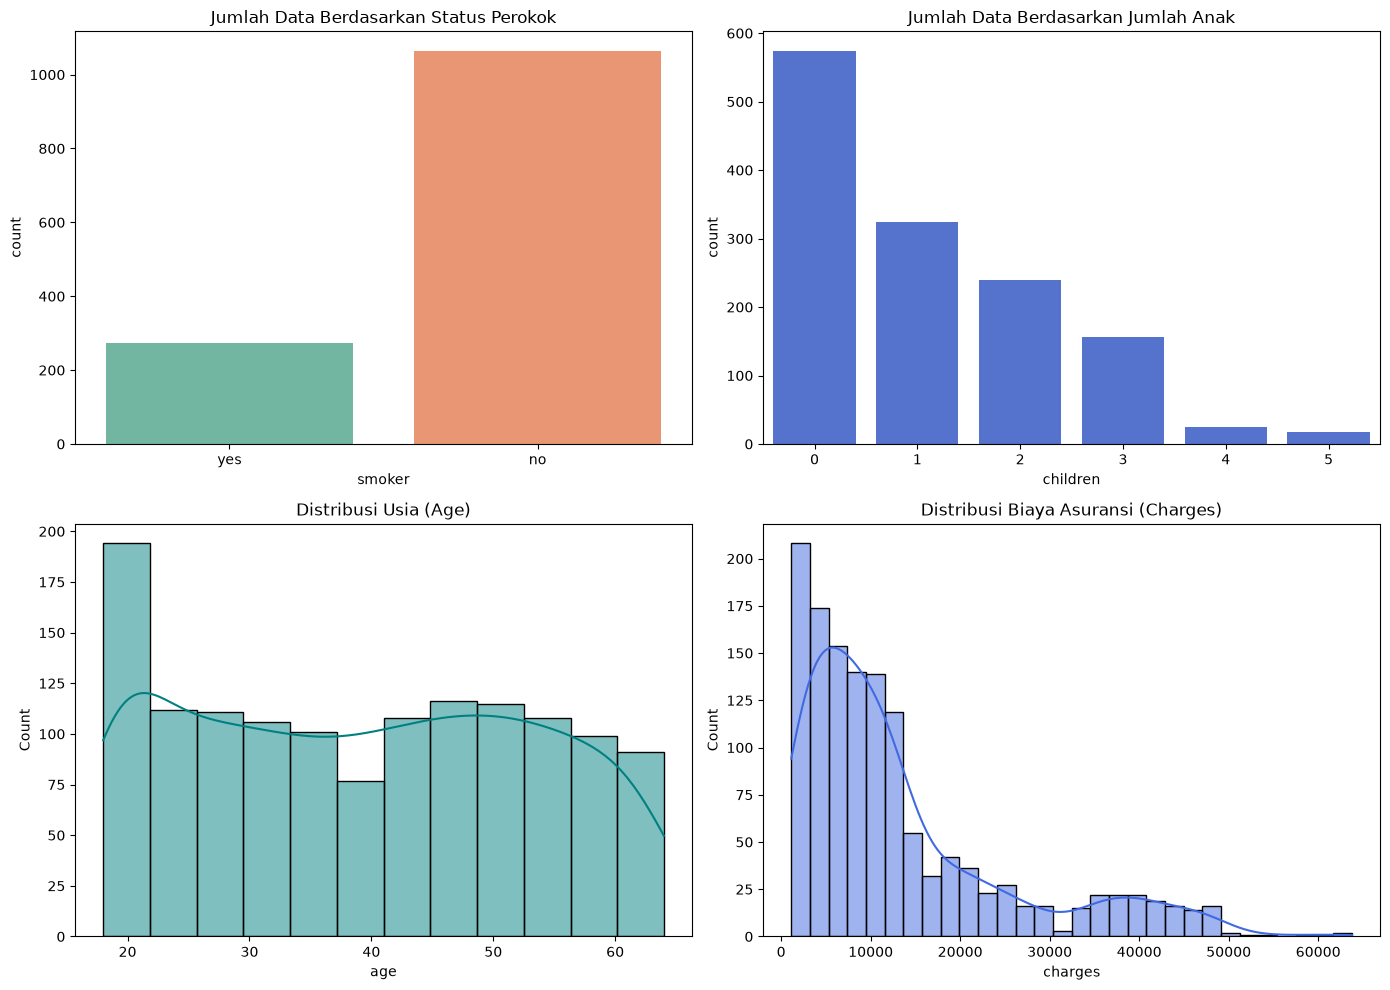

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.countplot(data=df, x='smoker', hue='smoker', legend=False, ax=axes[0, 0], palette='Set2')
axes[0, 0].set_title('Jumlah Data Berdasarkan Status Perokok')

sns.countplot(data=df, x='children', ax=axes[0, 1], color='royalblue')
axes[0, 1].set_title('Jumlah Data Berdasarkan Jumlah Anak')

sns.histplot(df['age'], kde=True, ax=axes[1, 0], color='teal')
axes[1, 0].set_title('Distribusi Usia (Age)')

sns.histplot(df['charges'], kde=True, ax=axes[1, 1], color='royalblue')
axes[1, 1].set_title('Distribusi Biaya Asuransi (Charges)')

plt.tight_layout()
plt.show()

# Preprosessing dan Seleksi Fitur 

In [5]:
df['smoker'] = np.where(df['smoker'].isin(['yes', 1]), 1, 0)

features = ['age', 'bmi', 'children', 'smoker']
x= df[features]
y= df['charges']

print("Dimensi x:", x.shape)
print("Dimensi y:", y.shape)

Dimensi x: (1338, 4)
Dimensi y: (1338,)


# Split data training dan testing

In [6]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=70
)
print("jumlah data training:", x_train.shape[0])
print("jumlah data testing:", x_test.shape[0])

jumlah data training: 1070
jumlah data testing: 268


# Training model Regresi Linier dan cek akurasi

In [7]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression ()
lr.fit(x_train, y_train)
pred = lr.predict(x_test)

score = lr.score(x_test, y_test)
print("Akurasi model regresi linier =", score)

Akurasi model regresi linier = 0.6723941439750623


# Uji coba input manual dan simpan model

In [8]:
import pickle

input_data = np.array([[30, 28.5, 1, 0]])
prediction = lr.predict(input_data)

usd = prediction[0]
idr = usd * 18000

print(f"Estimasi biaya asuransi (USD): $ {usd:,.2f}")
print(f"Estimasi biaya asuransi (IDR): Rp {idr:,.0f}")

filename = 'estimasi_asuransi.sav'
pickle.dump(lr, open(filename, 'wb'))
print("Model berhasil disimpan:", filename)

Estimasi biaya asuransi (USD): $ 5,242.97
Estimasi biaya asuransi (IDR): Rp 94,373,538
Model berhasil disimpan: estimasi_asuransi.sav


c:\python-3.11.9\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
